In [ ]:
!pip install split-folders

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
import keras
import splitfolders
from keras.models import Sequential
from keras.layers import Conv2D,Flatten,Dense,MaxPooling2D
from keras.preprocessing.image import ImageDataGenerator

In [ ]:
path='/content/drive/MyDrive/dataset'
splitfolders.ratio(path,output='/content/drive/MyDrive/data_output',seed=42,ratio=(0.8,0.1,0.1))

Copying files: 428 files [00:05, 74.62 files/s]


In [107]:
datagen=ImageDataGenerator(fill_mode='nearest',
                           zoom_range=0.2,
                           horizontal_flip=True)
x_train_dataset = datagen.flow_from_directory('/content/drive/MyDrive/data_output/train',
                                              batch_size=100,
                                              shuffle=True,
                                              target_size=(256,256))
x_train,y_train=x_train_dataset.next()

Found 342 images belonging to 3 classes.


In [108]:
x_test_dataset=datagen.flow_from_directory('/content/drive/MyDrive/data_output/test',
                                           batch_size=100,
                                           shuffle=True,
                                           target_size=(256,256))
x_test,y_test=x_test_dataset.next()

Found 44 images belonging to 3 classes.


In [109]:
x_val_dataset=datagen.flow_from_directory('/content/drive/MyDrive/data_output/val',
                                          batch_size=100,
                                          shuffle=True,
                                          target_size=(256,256))
x_val,y_val=x_val_dataset.next()

Found 42 images belonging to 3 classes.


In [110]:
y_test=y_test.astype('int32')
y_train=y_train.astype('int32')
y_val=y_val.astype('int32')

In [111]:
print("x_train_shape:",x_train.shape)
print("y_train_shape:",y_train.shape)
print("x_test_shape:",x_test.shape)
print("y_test_shape:",y_test.shape)

x_train_shape: (100, 256, 256, 3)
y_train_shape: (100, 3)
x_test_shape: (44, 256, 256, 3)
y_test_shape: (44, 3)


In [112]:
from keras.layers import AveragePooling2D
model = Sequential()
model.add(Conv2D(32,kernel_size=(3, 3), activation='relu', input_shape=(256,256,3)))
model.add(Flatten())
model.add(Dense(100,activation='relu'))
model.add(Dense(80, activation='relu'))
model.add(Dense(120, activation='relu'))
model.add(Dense(3, activation = 'softmax'))


In [113]:
model.compile(optimizer = 'adam',
              loss = 'categorical_crossentropy',
              metrics=['accuracy'])

In [114]:
model.summary()

Model: "sequential_6"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_9 (Conv2D)           (None, 254, 254, 32)      896       
                                                                 
 flatten_6 (Flatten)         (None, 2064512)           0         
                                                                 
 dense_18 (Dense)            (None, 100)               206451300 
                                                                 
 dense_19 (Dense)            (None, 80)                8080      
                                                                 
 dense_20 (Dense)            (None, 120)               9720      
                                                                 
 dense_21 (Dense)            (None, 3)                 363       
                                                                 
Total params: 206,470,359
Trainable params: 206,470,35

In [85]:
model.fit(x_train,y_train,epochs=10,validation_split=0.20)

Epoch 1/10
3/3 [==============================] - 15s 4s/step - loss: 5070.1650 - accuracy: 0.4625 - val_loss: 7971.5938 - val_accuracy: 0.4000
Epoch 2/10
3/3 [==============================] - 12s 4s/step - loss: 6393.5479 - accuracy: 0.4250 - val_loss: 2654.8403 - val_accuracy: 0.4000
Epoch 3/10
3/3 [==============================] - 11s 4s/step - loss: 1667.0992 - accuracy: 0.3125 - val_loss: 2351.4705 - val_accuracy: 0.3500
Epoch 4/10
3/3 [==============================] - 13s 3s/step - loss: 1422.4271 - accuracy: 0.3625 - val_loss: 1703.3051 - val_accuracy: 0.3500
Epoch 5/10
3/3 [==============================] - 13s 5s/step - loss: 883.4777 - accuracy: 0.5625 - val_loss: 672.0257 - val_accuracy: 0.3500
Epoch 6/10
3/3 [==============================] - 13s 4s/step - loss: 397.0746 - accuracy: 0.5125 - val_loss: 1013.3582 - val_accuracy: 0.4000
Epoch 7/10
3/3 [==============================] - 12s 4s/step - loss: 430.1385 - accuracy: 0.6125 - val_loss: 415.8327 - val_accuracy: 0.25

In [86]:
test=model.evaluate(x_test,y_test)
print("Test Accuracy:",test[1])
print("Loss:",test[0])

2/2 [==============================] - 2s 360ms/step - loss: 413.2882 - accuracy: 0.4773
Test Accuracy: 0.47727271914482117
Loss: 413.2881774902344


In [87]:
train=model.evaluate(x_train,y_train)
print("Train Accuracy:",train[1])
print("Loss:",train[0])

4/4 [==============================] - 3s 677ms/step - loss: 78.6602 - accuracy: 0.8100
Train Accuracy: 0.8100000023841858
Loss: 78.66023254394531


In [88]:
val=model.evaluate(x_val,y_val)
print("Val Accuracy:",val[1])
print("Loss:",val[0])

2/2 [==============================] - 1s 318ms/step - loss: 286.5735 - accuracy: 0.5238
Val Accuracy: 0.523809552192688
Loss: 286.5735168457031


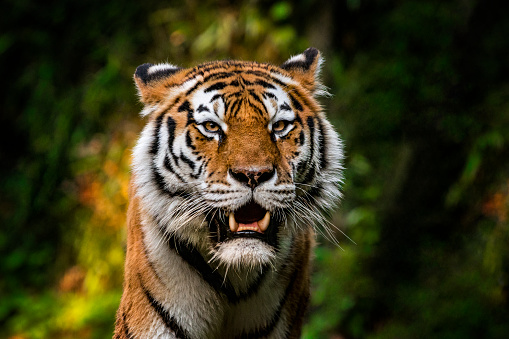

Image Shape: (339, 509, 3)


In [97]:
#prediction
import cv2
from google.colab.patches import cv2_imshow
img=cv2.imread('/content/drive/MyDrive/tiger.jpg')
cv2_imshow(img)
print("Image Shape:",img.shape)

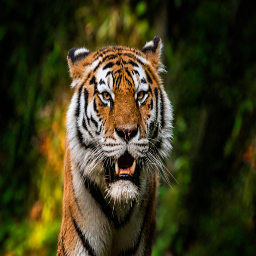

Image Shape: (256, 256, 3)


In [98]:
#Resize
re=cv2.resize(img,(256,256))
#reshape
im=re.reshape(-1,256,256,3)
cv2_imshow(re)
print("Image Shape:",re.shape)

In [99]:
p=model.predict(im)

1/1 [==============================] - 0s 281ms/step


In [100]:
print(np.argmax(p))

0


Class Labels   
Cats=0
dogs=1
tiger=2